# Exercices 5

[Télécharger l'exercice](../05_exercice.zip)

# Exercise : Intrusion magmatique 

Le but de cet exercice est de modéliser deux intrusions magmatiques successives qui réchauffent la roche environnante en résolvant un problème de diffusion. Ce problème peut être simplifié en une dimension (1D) où la dimension $x$ représente la distance orthogonale aux intrusions.
 
![](./fig/dykes.png)

*Figure 1: Représentation des deux intrusions successives et la diffusion de leur chaleur dans la roche environnante.*

Les deux intrusions s'infiltrent l'une après l'autre à une profondeur d'environ 1 km, où la roche encaissante a une température de 30°C. La température initiale des intrusions est de 1000°C, et le magma commence à refroidir dès son arrivée à cet emplacement. La seconde intrusion s'infiltre 15 ans plus tard, à 30 m à droite de la première (mesurée entre leurs centres). La première intrusion a une épaisseur de 24 m, tandis que la seconde mesure 10 m d'épaisseur. La simulation débute immédiatement après la formation de la première intrusion. Aux deux extrémités (gauche et droite) de l'espace à modéliser, la roche est fracturée et traverse un flux d'eau important, maintenant ainsi une température constante de 30°C.

Pour résoudre ce problème, il faut discrétiser et implémenter les mêmes équations de diffusion thermique :

$$ q = -D \frac{\partial T}{dx}, \qquad (1) $$
$$ \frac{\partial T}{\partial t} = -\frac{\partial q}{\partial x}. \qquad (2) $$

Les paramètres physiques sont donnés dans la table suivante :

**Table: paramètres du modèle**

| **Paramètres**                | **Valeurs**         |
|-------------------------------|---------------------|
| Température ambiante          | 30°C                |
| Température de l'intrusion    | 1000°C              |
| Température limite gauche     | 30°C                |
| Température limite droite     | 30°C                |
| Centre de l'intrusion 1       | 80 m                |
| Centre de l'intrusion 2       | 110 m               |
| Épaisseur de l'intrusion 1    | 24 m                |
| Épaisseur de l'intrusion 2    | 10 m                |
| Intrusion de l'intrusion 2    | 15 ans              |
| Diffusivité de la roche       | 50 m²/yr            |
| Longueur du modèle            | 200 m               |

Écrire un code afin de répondre aux questions suivantes. Il s'agit d'écrire un code unique, avec un paramètre `Q` défini à `1` ou `2` pour traiter les questions 1 et 2.

**Q1 :** Après combien de temps une sonde positionnée 80 m à droite du centre de la première intrusion enregistrera une température de 100°C ? Stoppez votre code quand cette condition est remplie. 

**Q2 :** Changez les deux conditions de bords en supposant un flux nul de chaleur et refaites l'expérience. Analysez l'influence des conditions de bords sur le temps de passage de la sonde au-delà de 100°C.

### ✅ **À vous de faire !** 

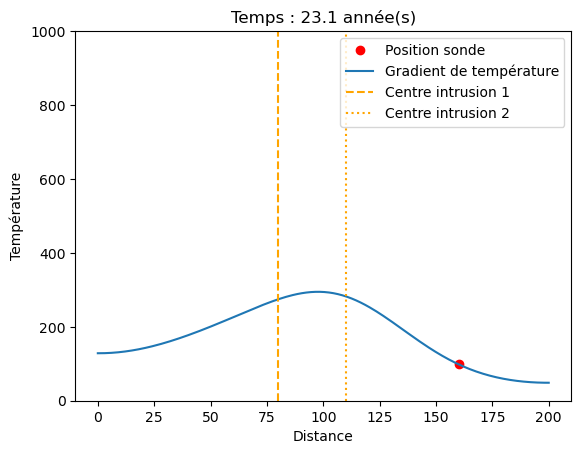

La température à la position de la sonde a dépasse 100°C après 23.30 ans


In [4]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import clear_output, display

# Version du code à effectuer
Q = 2

# Paramètres physiques
D = 50                  # Diffusivité de la roche (m2/an)
Tamb = 30               # Température ambiante (en °C)
Tint = 1000             # Température des intrusions (en °C)
Tlim_g = 30             # Température au bord gauche
Tlim_d = 30             # Température au bord droit
Tthr = 100              # Température limite (sonde)
xint1 = 80              # Position du centre de l'intrusion 1 (en m)
xint2 = 110             # Position du centre de l'intrusion 2 (en m)
wint1 = 24              # Largeur (width) de l'intrusion 1 (en m)
wint2 = 10              # Largeur (width) de l'intrusion 2 (en m)
xsonde = 160            # Position sonde (en m)
tint2 = 15              # Temps intrusion 2 (en années)
ttot = 100              # Temps total de la modélisation
Lx = 200                # Longueur du modèle (en m)

# Paramètres numériques
nx = 200                      # nombre de cellules
dx = Lx / (nx - 1)            # taille d'une cellule
x = np.linspace(0, Lx, nx)    # coordonees des point du maillage
dt = dx**2 / (2.1 * D)        # condition sur le pas de temps
nt = int(ttot/dt)                  # nombre de pas de temps
nout = 100                    # afficher la figure chaque 100e step

# Initialisation
T = np.ones(nx) * Tamb
T[int(xint1-(wint1/2)/dx):int(xint1+(wint1/2)/dx)] = Tint
time = 0

# Flags
flag_int = 0

# create the figure outside the loop 
fig, ax = plt.subplots()

# loop
for it in range(nt):
    # Suivi du temps
    time += dt
    # Mettre a jour le flux q en fonction de C 
    q = - D * ( T[1:] - T[:-1] ) / dx
    # Mettre a jour dCdt
    dTdt = - ( q[1:] - q[:-1] ) / dx    
    # Mettre a jour C
    T[1:-1] += dTdt * dt

    # Conditions de bord
    if Q == 1:
        T[0] = Tlim_g   # Température constante
        T[-1] = Tlim_d
    if Q == 2:
        T[0] = T[1]     # Flux nul
        T[-1] = T[-2]

    # Condition pour la deuxième intrusion
    if time >= tint2 and flag_int == 0:
        T[int(xint2-(wint2/2)/dx):int(xint2+(wint2/2)/dx)] = Tint
        flag_int = 1
    
    # Condition d'arrêt (sonde dépasse 100°C)
    if T[int(xsonde/dx)] >= Tthr:
        print(f'La température à la position de la sonde a dépasse {Tthr}°C après {time:.2f} ans')
        break

    # plot
    if it % nout == 0:
        clear_output(wait=True) 
        ax.cla() 
        ax.set_ylim(0, 1000)
        ax.plot(xsonde, Tthr, 'ro', label='Position sonde')
        ax.set_title('Temps : ' + str(round(time, 2)) + ' année(s)')
        ax.plot(x, T, label='Gradient de température')
        ax.set_xlabel('Distance')
        ax.set_ylabel('Température')
        ax.axvline(xint1, color='orange', linestyle='--', label='Centre intrusion 1')
        if time >= tint2:
            ax.axvline(xint2, color='orange', linestyle=':', label='Centre intrusion 2')

        ax.legend(loc='upper right')
        display(fig)
        plt.pause(0.1) 
